In [ ]:
#libraries
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from matplotlib.colors import LinearSegmentedColormap
from dash import Dash, html, dcc, callback, Output, Input
import dash_ag_grid as dag
import plotly.express as px

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

# Setting seaborn style
main_color = "#4A90C2"
colors = ["#2F5D7C", "#4A90C2", "#F6CF6B", "#FAA85E", "#F26B4E"]
sns.set_theme(style="ticks", palette=colors)

<b><font size="6" color="#FAA85E">1.Data Exploration and Initial Analysis</font></b><br>

In [ ]:
df_raw = pd.read_csv("../data/acdc_dataset.csv", sep=";", index_col="member_id")
df = df_raw.copy()
df_raw.head()


In [33]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

In [34]:
df_raw.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

In [35]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


In [36]:
df_raw.describe(include="bool").T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


In [37]:
df_raw.describe(include="object").T
#plan tier should only have 5 unique values
#gender shou have 3: Female, Male, Other

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


<b><font size="6" color="#FAA85E">2.Data Quality Checks</font></b><br>

In [38]:
df['membership_start'] = pd.to_datetime(df["membership_start"], format='mixed')
df['membership_end'] = pd.to_datetime(df["membership_end"], format='mixed')
df['last_badge_swipe'] = pd.to_datetime(df["last_badge_swipe"], format='mixed')

We turned the variable `lifetime_value` to a float. The variable had symbols that made them into an object type.

In [39]:
df["lifetime_value"] = (
    df["lifetime_value"]
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

In [40]:
df_raw["uses_print"].unique()

array([0, 1])

`uses_print` only has the values 1 and 0, so we turn it into a boolean type.

In [41]:
df["uses_print"] = df["uses_print"].astype("boolean")
df["uses_print"].dtype

BooleanDtype

In [42]:
df.isna().sum()[lambda s: s > 0]

age                     558
gender                  530
country                 430
plan_tier               105
meeting_room_hours     1298
guest_passes_issued    1271
lifetime_value         1040
dtype: int64

In [43]:
#Turning object values to lower case
cols_object = df.select_dtypes(include="object").columns
df[cols_object] = df[cols_object].apply(lambda s: s.str.lower())

print(f"Gender unique values: {df["gender"].unique()}")
print(f"Country unique values: {df["country"].unique()}")
print(f"Plan tier unique values: {df["plan_tier"].unique()}")
print(f"Industry unique values: {df["industry"].unique()}")

Gender unique values: ['female' 'male' 'f' 'other' nan ' female' 'm' ' male' ' other' 'o']
Country unique values: ['portugal' 'de' 'united kingdom' 'spain' 'germany' 'netherlands' 'france'
 'pt' 'other (europe)' 'portucal' nan 'uk' 'ireland' 'ie' 'portugal '
 'deutschland' 'u.k.' 'gb' 'es' 'nl' 'españa' 'espana' 'the netherlands'
 'fr' 'holland']
Plan tier unique values: ['flex' 'hot_desk' 'dedicated_desk' 'full_time' 'private_office'
 'hot desk' 'dedicateddesk' nan 'hotdesk' 'fulltime' 'privateoffice'
 'full time' 'dedicated desk' 'private office']
Industry unique values: ['information technology' 'education' 'legal' 'health' 'unknown' 'other'
 'consulting' 'design & creative' 'finance' 'marketing & pr'
 'marketing and pr' 'real estate' 'marketing/pr' 'design/creative'
 'realestate' 'it' 'tech' 'design and creative' 'real-estate']


In [44]:
#Replacing gender values
df["gender"] = df["gender"].replace([" female", "f"], "female")
df["gender"] = df["gender"].replace([" male", "m"], "male")
df["gender"] = df["gender"].replace([" other", "o"], "other")

#Replacing country values
df["country"] = df["country"].replace({
    "portucal":"portugal", "portugal ":"portugal", "pt":"portugal",
    "de":"germany", "deutschland":"germany",
    "uk":"united kingdom", "u.k.":"united kingdom", "gb":"united kingdom",
    "es":"spain", "españa":"spain", "espana":"spain",
    "nl":"netherlands", "the netherlands":"netherlands", "holland":"netherlands",
    "fr":"france",
    "ie":"ireland"})

#Replacing Plan tier values
df["plan_tier"] = df["plan_tier"].replace(["hotdesk", "hot desk"], "hot_desk")
df["plan_tier"] = df["plan_tier"].replace(["dedicateddesk", "dedicated desk"], "dedicated_desk")
df["plan_tier"] = df["plan_tier"].replace(["fulltime", "full time"], "full_time")
df["plan_tier"] = df["plan_tier"].replace(["privateoffice", "private office"], "private_office")

#Replacing Industry values
df["industry"] = df["industry"].replace(["it", "tech"], "information technology")
df["industry"] = df["industry"].replace(["design & creative", "design/creative"], "design and creative")
df["industry"] = df["industry"].replace(["marketing & pr", "marketing/pr"], "marketing and pr")
df["industry"] = df["industry"].replace(["realestate", "real-estate"], "real estate")

df.describe(include="object").T

,count,unique,top,freq
gender,14935,3,female,7867
industry,15465,11,information technology,3559
country,15035,8,portugal,10508
plan_tier,15360,5,flex,5453


In [45]:
df.duplicated().sum()

np.int64(295)

In [46]:
df_nodups = df.drop_duplicates()

In [47]:
bool_cols = ['is_team_account',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker']

add_ons = [c for c in bool_cols if c != 'is_team_account']

df_nodups['n_add_on'] = df_nodups[add_ons].sum(axis=1)

/var/folders/95/1xf01h296vjbznnd0l4gq4300000gn/T/ipykernel_4479/4202460851.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nodups['n_add_on'] = df_nodups[add_ons].sum(axis=1)


In [48]:
non_metric_features = ['gender', 'country', 'industry', 'plan_tier', 'is_team_account',
 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes',
 'uses_storage', 'uses_bike_locker']

metric_features = df_nodups.columns.drop(non_metric_features).to_list()

<b><font size="6" color="#FAA85E">3.Metric Features Visualization</font></b><br>

<b><font size="5" color="#FAA85E">3.1. Unvariate Analysis</font></b><br>

<b><font size="4" color="#FAA85E">3.1.1. `age`</font></b><br>

In [2]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_age_filtered = df_nodups[(df_nodups["age"] > 17) & (df_nodups["age"] < 91)]

axes[0, 0].hist(df_nodups["age"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_age_filtered["age"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["age"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_age_filtered["age"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Age Distribution', fontweight="bold") 
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>=18 and <=90): Age Distribution', fontweight="bold") 
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Age Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Age')

axes[1, 1].set_title('Filtered (>=18 and <=90): Age Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Age')

plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<b><font size="5" color="#FAA85E">3.2. Correlation Matrix</font></b><br>

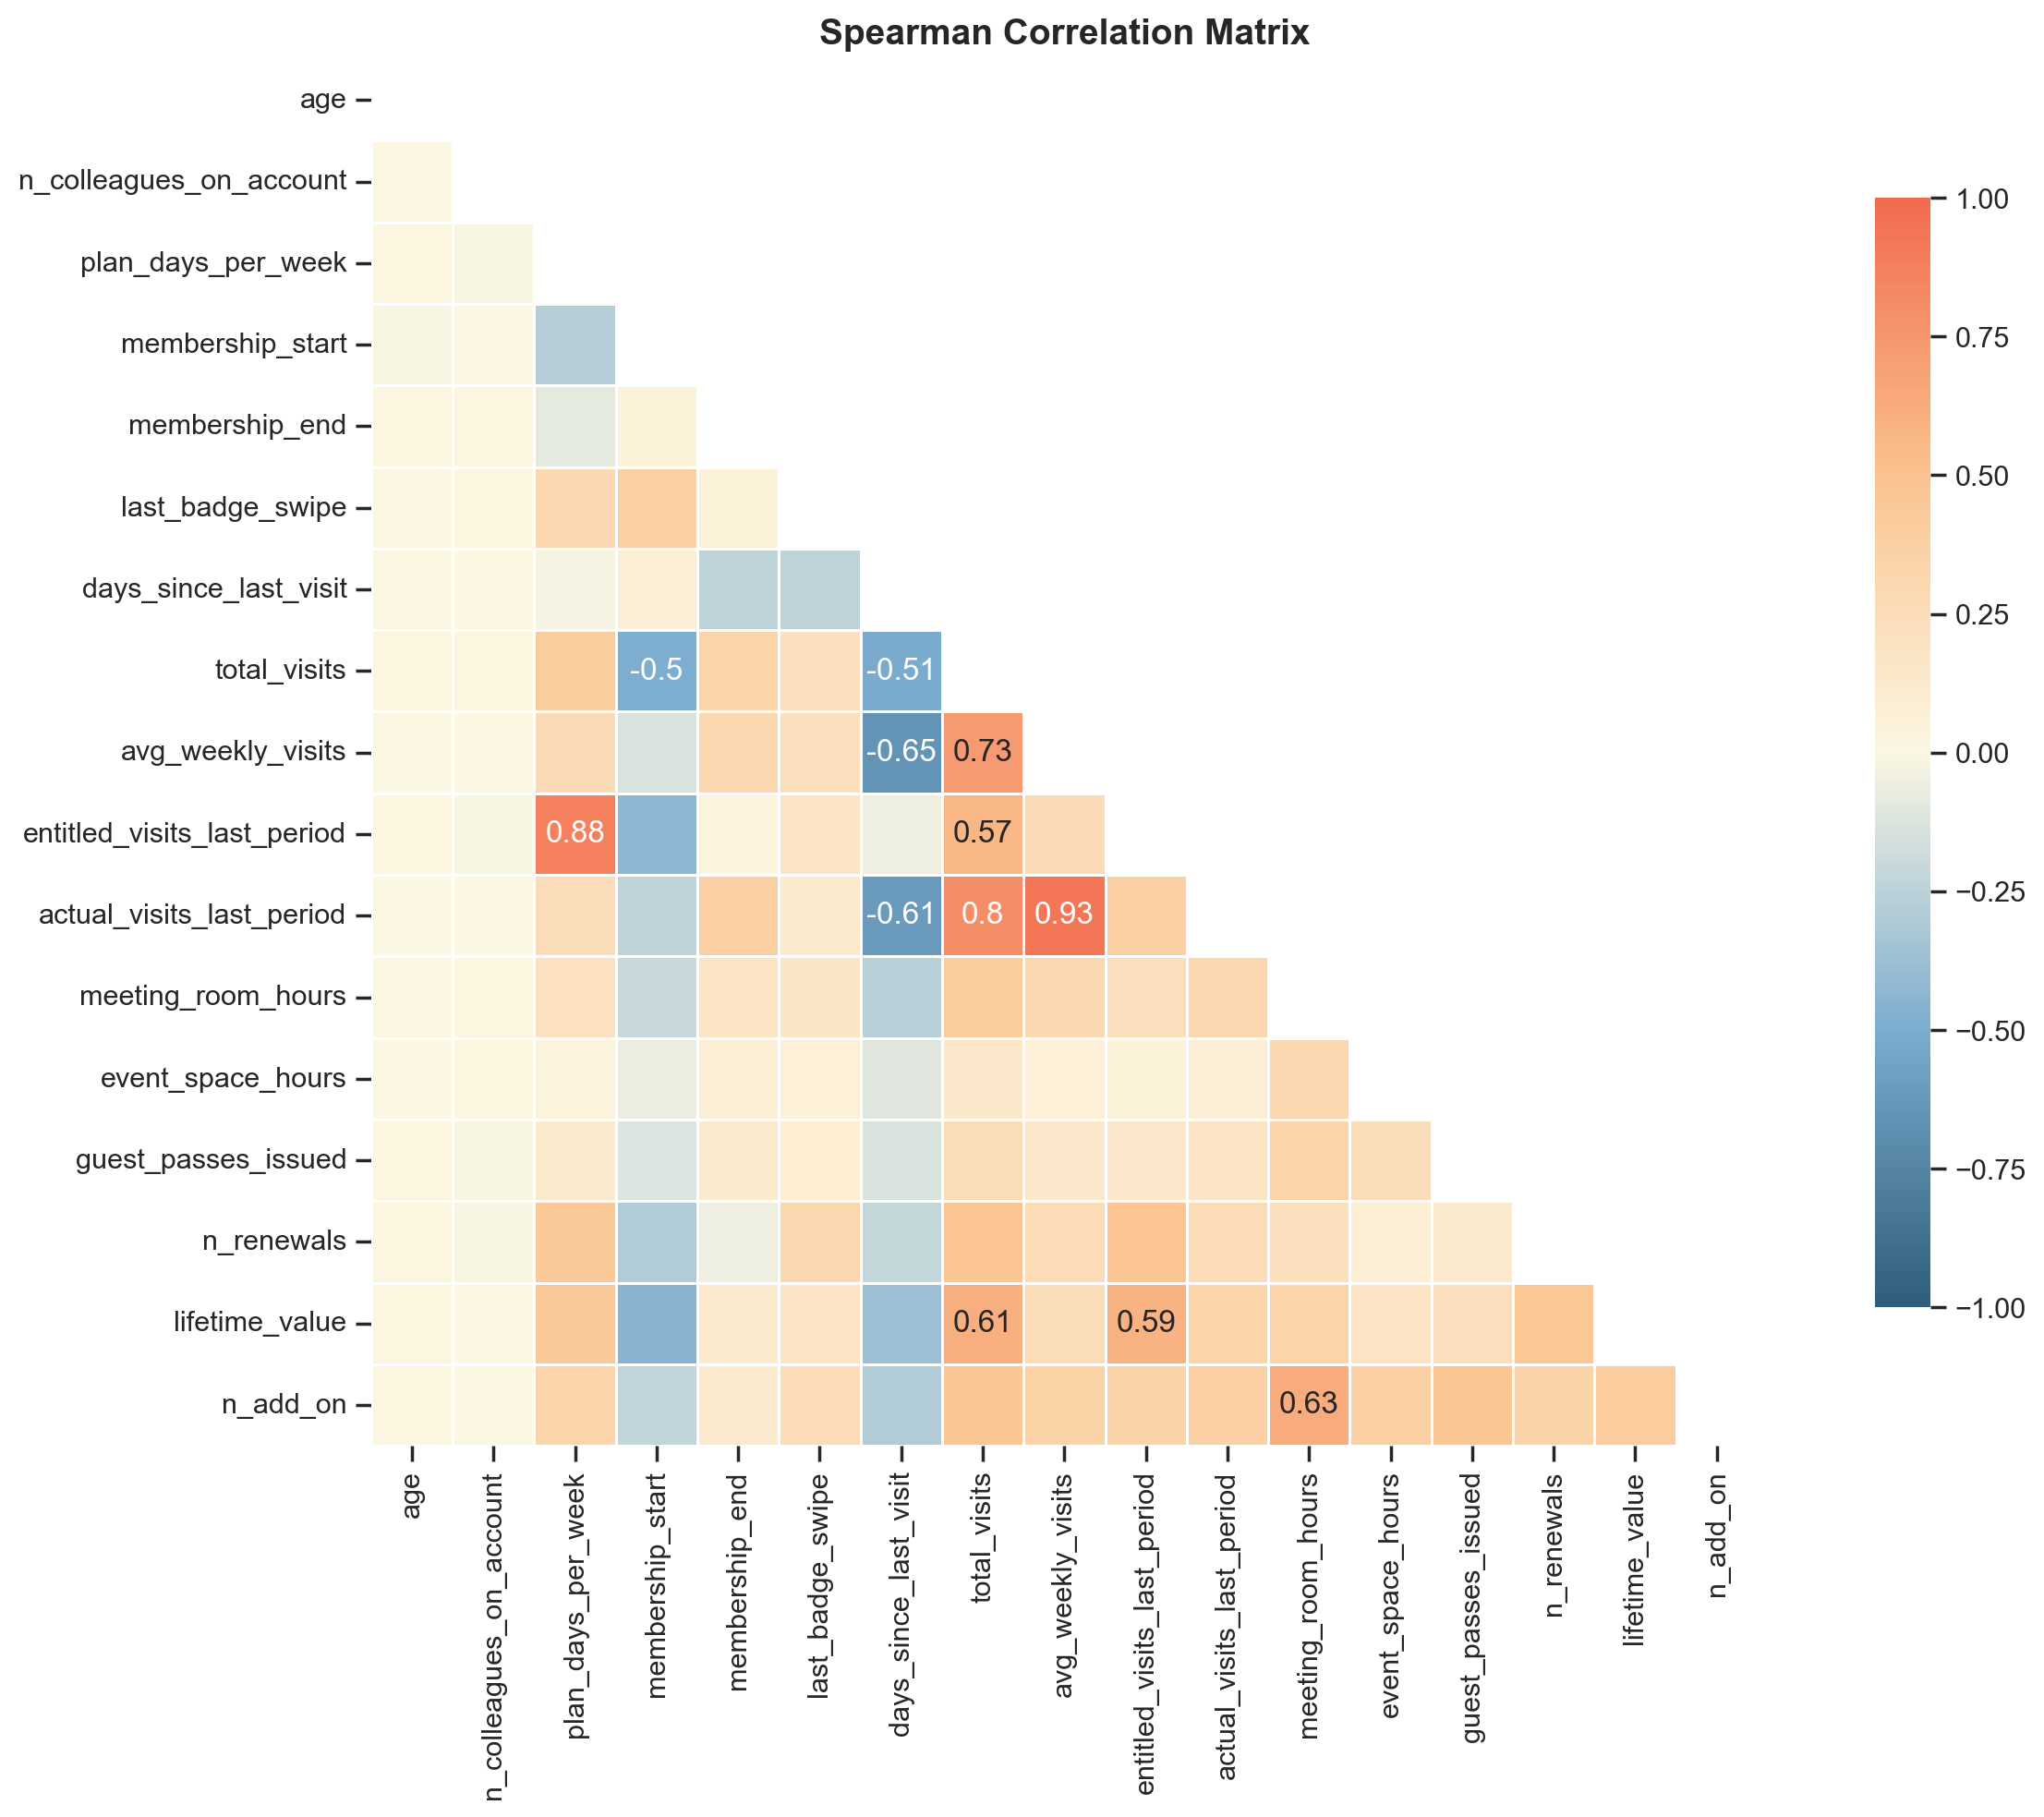

<Figure size 640x480 with 0 Axes>

In [49]:
cmap = LinearSegmentedColormap.from_list(
    "smooth_div",
    ["#2F5D7C", "#7CADCF", "#FCF7E3", "#FAC38F", "#F26B4E"],
    N=256,
)

corr = df_nodups[metric_features].corr(method="spearman").round(2)

# Lógica da aula para anotar apenas correlações fortes (>= 0.5 ou <= -0.5)
mask_annot = np.absolute(corr.values) >= 0.5 
annot = np.where(mask_annot, corr.values, np.full(corr.shape,"")) 

mask_upper = np.triu(np.ones_like(corr, dtype=bool))

fig = plt.figure(figsize=(14, 10))

sns.heatmap(
    data=corr, 
    annot=annot, 
    fmt='s', 
    mask=mask_upper,         
    vmin=-1, vmax=1, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cmap=cmap,              
    cbar_kws={"shrink": .8}   
)

plt.title("Spearman Correlation Matrix", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

if not os.path.exists(os.path.join('..', 'figures', 'eda')):
    # if the exp_analysis directory is not present then create it first
    os.makedirs(os.path.join('..', 'figures', 'eda'))
    
plt.savefig(os.path.join('..', 'figures', 'eda', 'numeric_variables_heatmap'), dpi=200)

plt.show()

Comparing the variables where correlation is bigger than 0.5 and less than -0.5

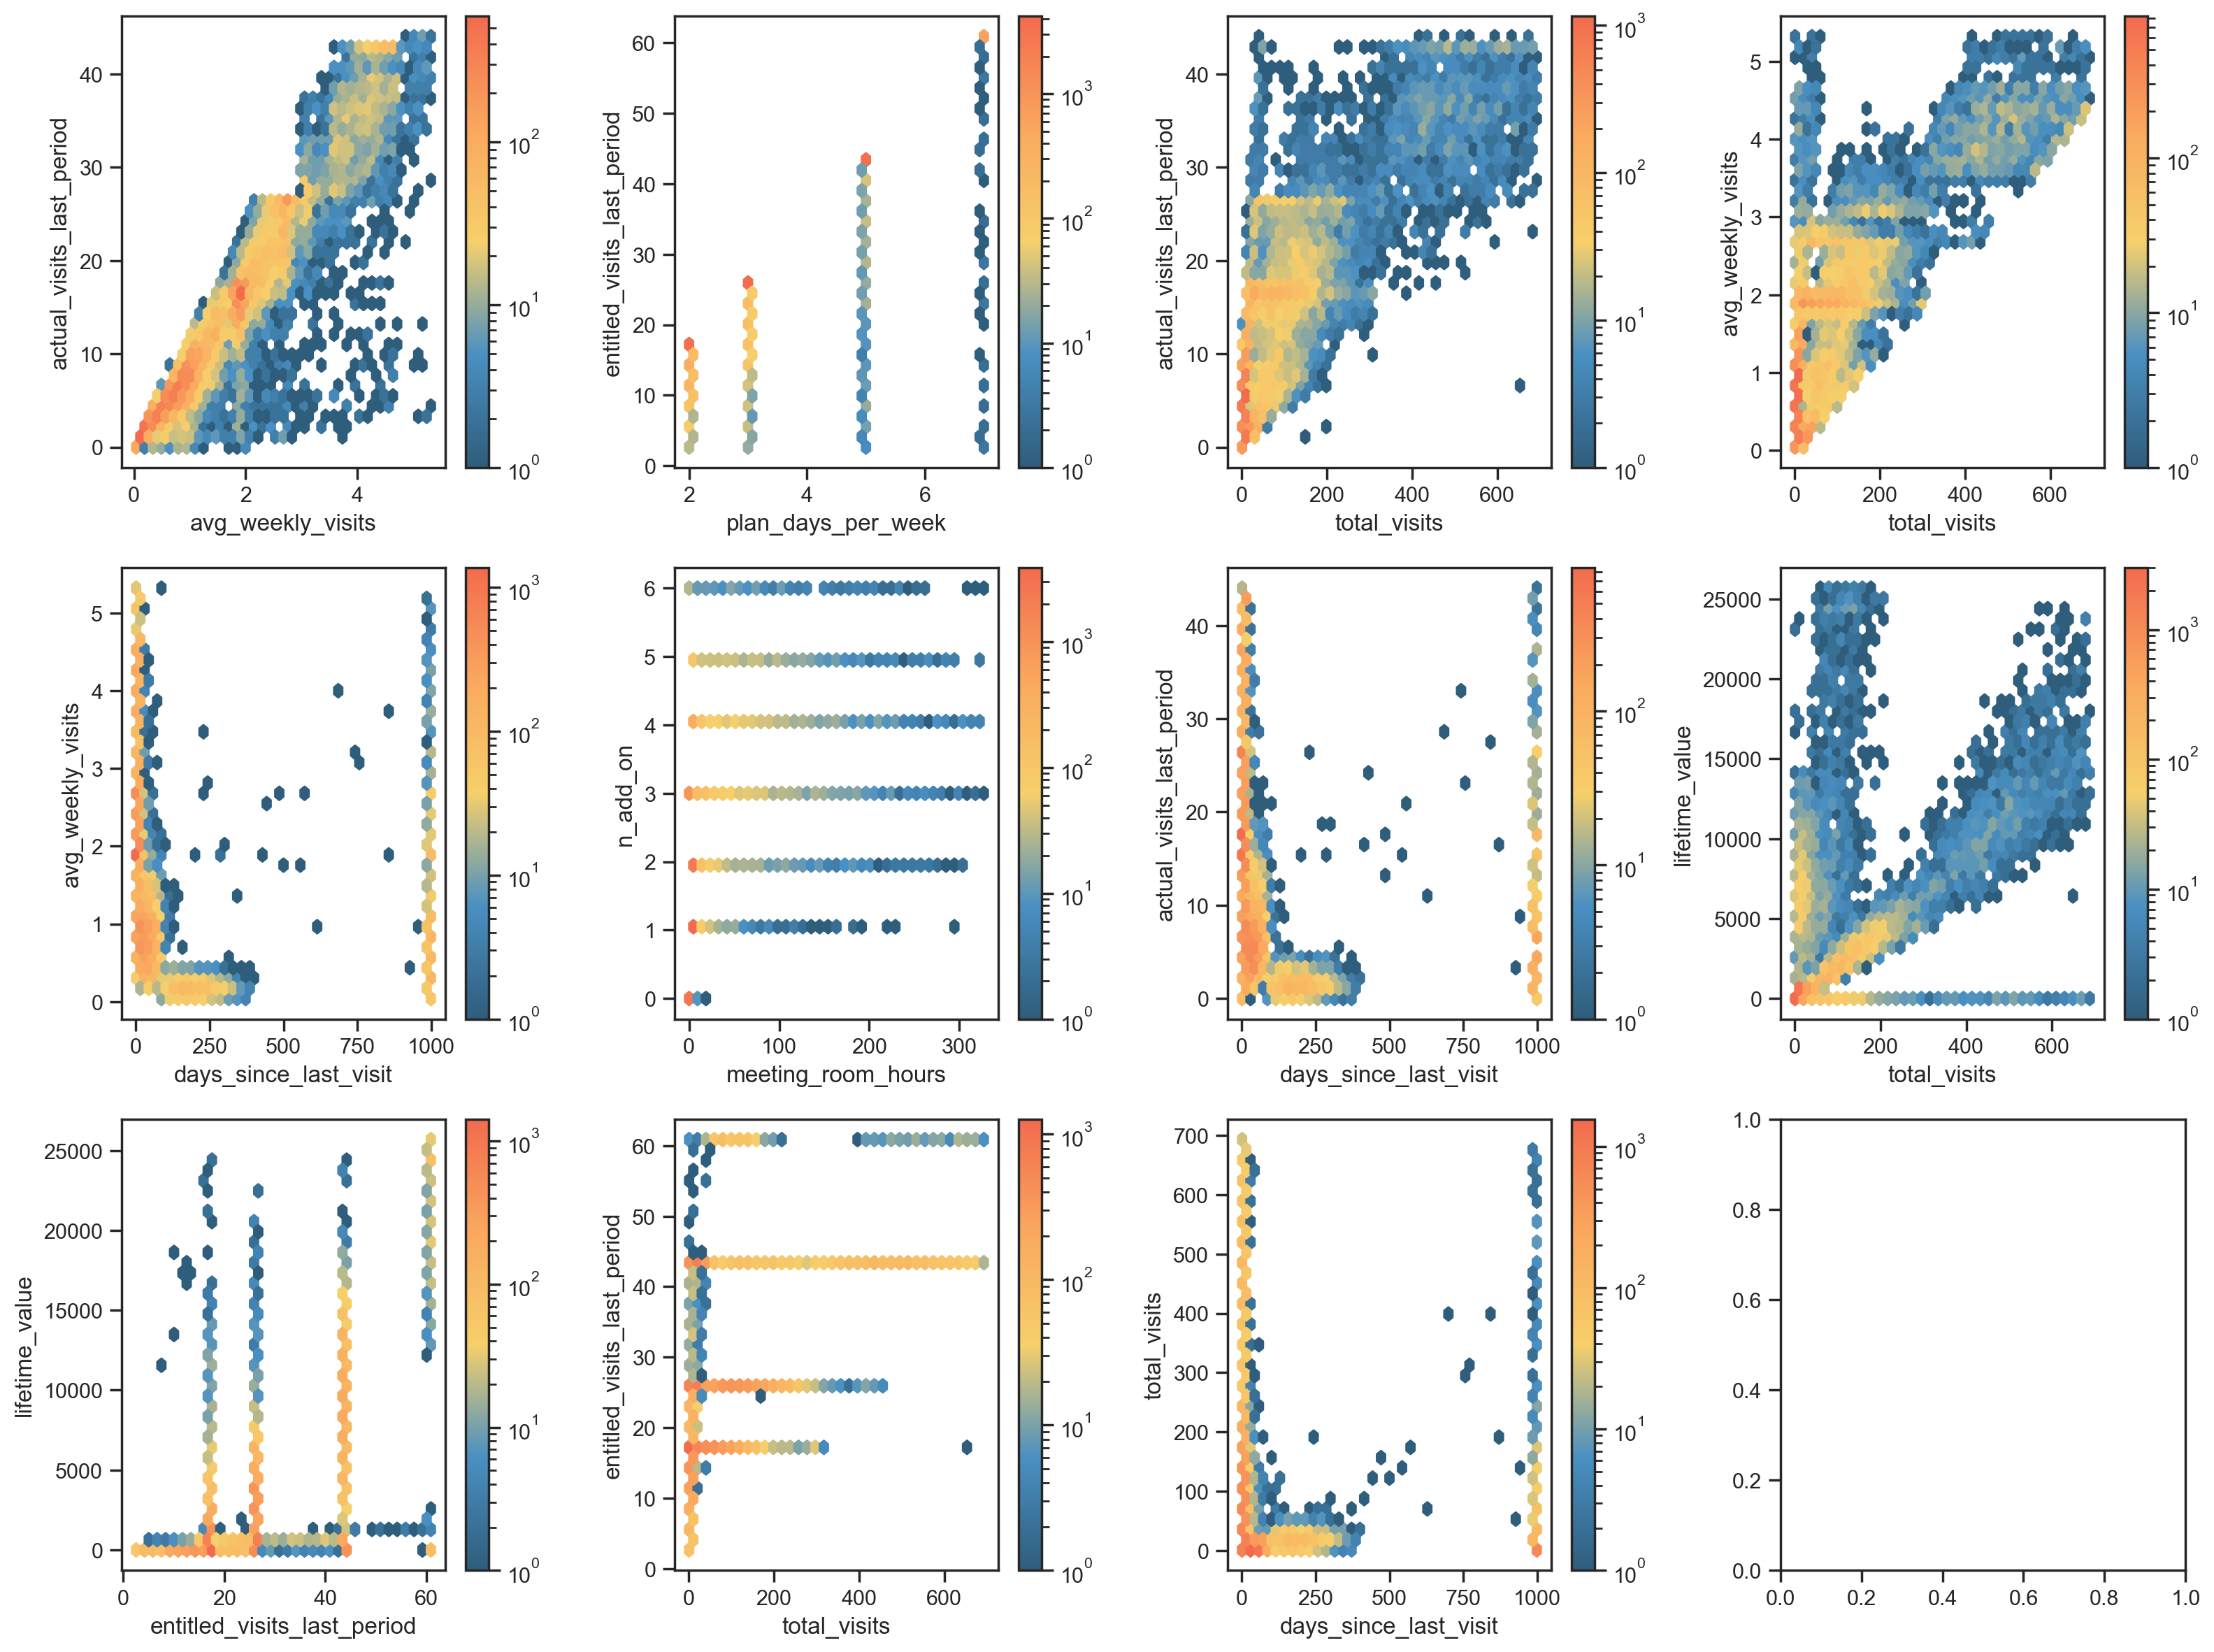

In [50]:
cmap_palette = LinearSegmentedColormap.from_list("custom", colors, N=256)
palette = [cmap_palette(i) for i in np.linspace(0, 1, 11)] 

pairs = [
    ("avg_weekly_visits", "actual_visits_last_period"),
    ("plan_days_per_week", "entitled_visits_last_period"),
    ("total_visits", "actual_visits_last_period"),
    ("total_visits", "avg_weekly_visits"),
    ("days_since_last_visit", "avg_weekly_visits"),
    ("meeting_room_hours", "n_add_on"),
    ("days_since_last_visit", "actual_visits_last_period"),
    ("total_visits", "lifetime_value"),
    ("entitled_visits_last_period", "lifetime_value"),
    ("total_visits", "entitled_visits_last_period"),
    ("days_since_last_visit", "total_visits"),
]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, (x, y) in zip(axes.flatten(), pairs):
    d = df_nodups[[x, y]].dropna()
    xlo, xhi = d[x].quantile([0.01, 0.99])
    ylo, yhi = d[y].quantile([0.01, 0.99])
    d = d[d[x].between(xlo, xhi) & d[y].between(ylo, yhi)]
    hb = ax.hexbin(d[x], d[y], gridsize=35, cmap=cmap_palette, bins="log", mincnt=1)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    fig.colorbar(hb, ax=ax)

plt.tight_layout()
plt.show()

<b><font size="5" color="#FAA85E">3.3. Bivariate Analysis</font></b><br>

<b><font size="6" color="#FAA85E">4. Date Features Visualization</font></b><br>

Customers analysed: 11093 of 15465
count    11093.0
mean       329.0
std        289.0
min          1.0
25%         69.0
50%        252.0
75%        536.0
max       1095.0
Name: tenure_days, dtype: float64


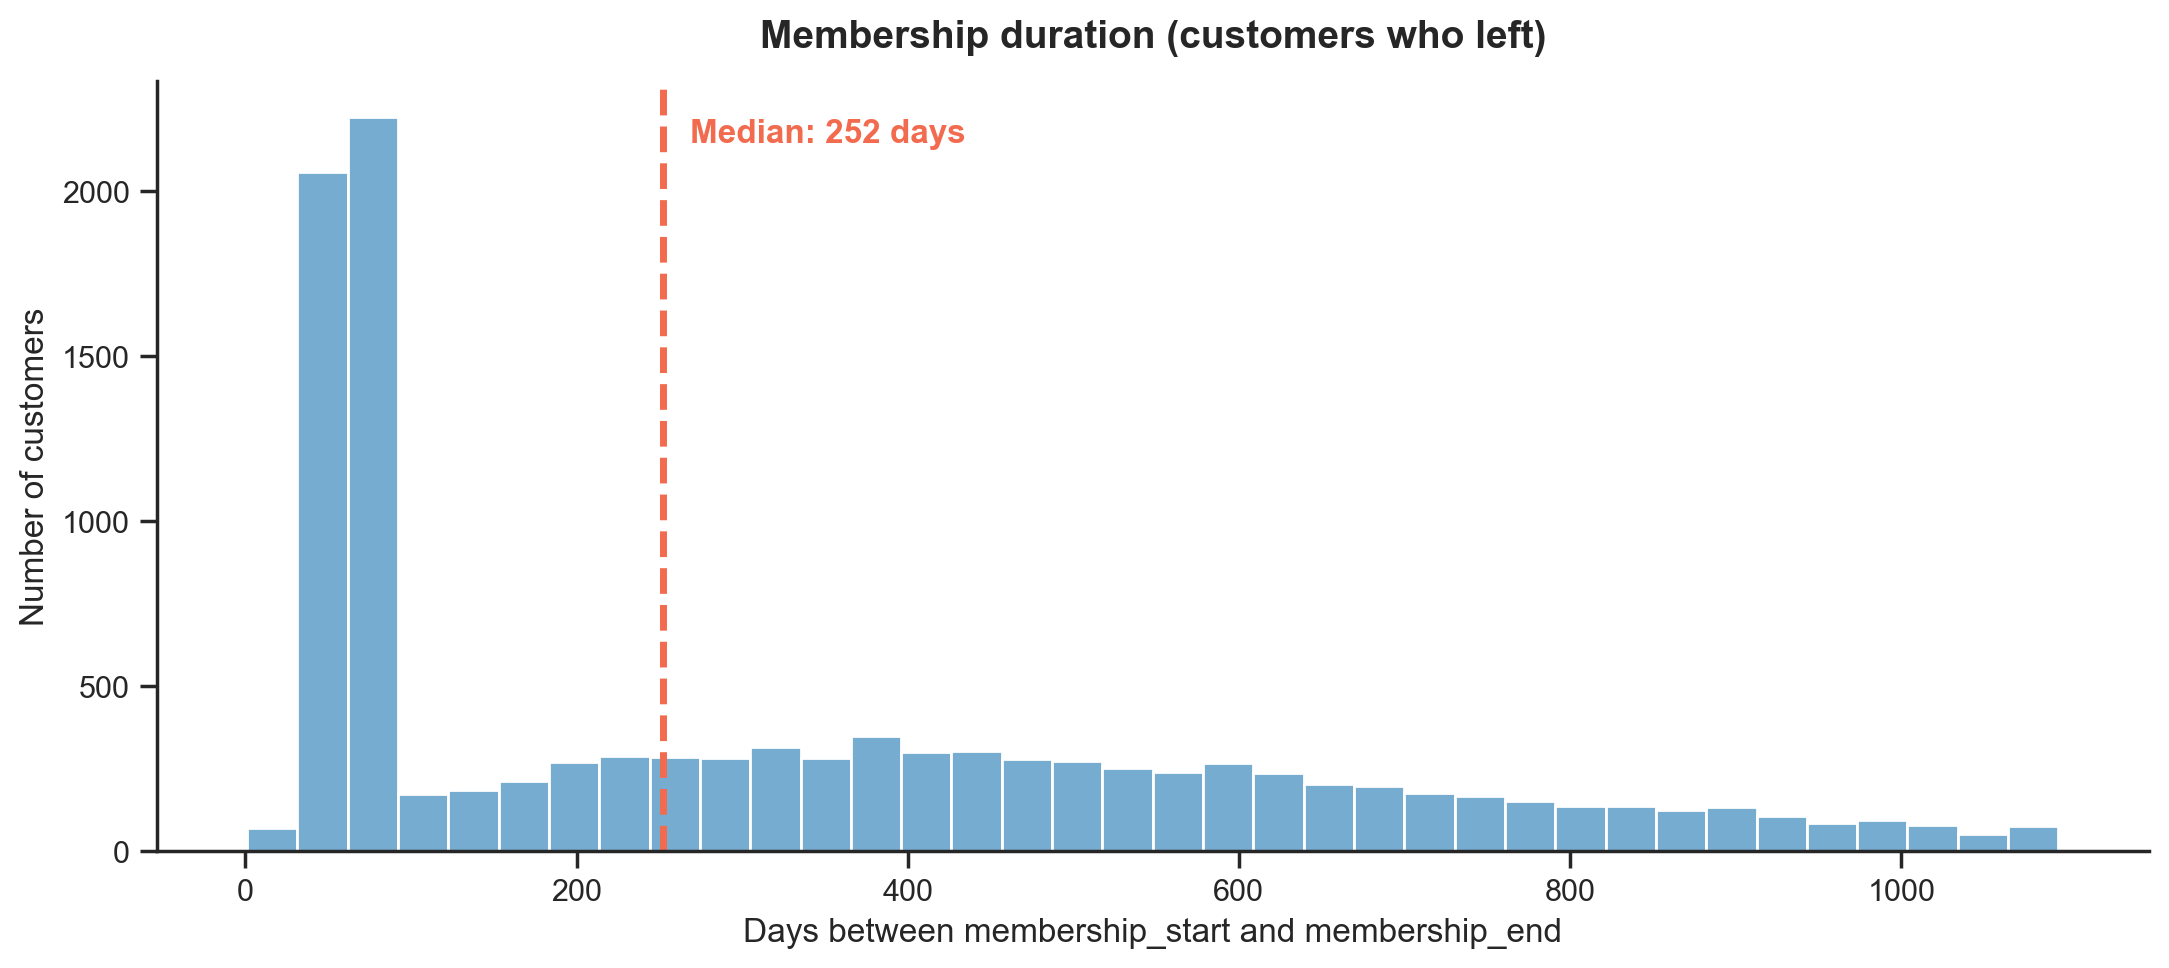

In [51]:
placeholder = pd.Timestamp("1970-01-01")

# só clientes que saíram (sem placeholder) e com datas coerentes
df_tenure = df_nodups.loc[
    (df_nodups["membership_end"] != placeholder) &
    (df_nodups["membership_end"] >= df_nodups["membership_start"])
].copy()

df_tenure["tenure_days"] = (df_tenure["membership_end"] - df_tenure["membership_start"]).dt.days

print(f"Customers analysed: {len(df_tenure)} of {len(df)}")
print(df_tenure["tenure_days"].describe().round(0))

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df_tenure["tenure_days"], bins=36, color=main_color, edgecolor="white", ax=ax)

median = df_tenure["tenure_days"].median()
ax.axvline(median, color="#F26B4E", linewidth=2.5, linestyle="--")
ax.annotate(f"Median: {median:.0f} days", xy=(median, ax.get_ylim()[1] * 0.92),
            xytext=(10, 0), textcoords="offset points", color="#F26B4E", fontweight="bold")

ax.set_title("Membership duration (customers who left)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Days between membership_start and membership_end")
ax.set_ylabel("Number of customers")
sns.despine()
plt.tight_layout()
plt.show()

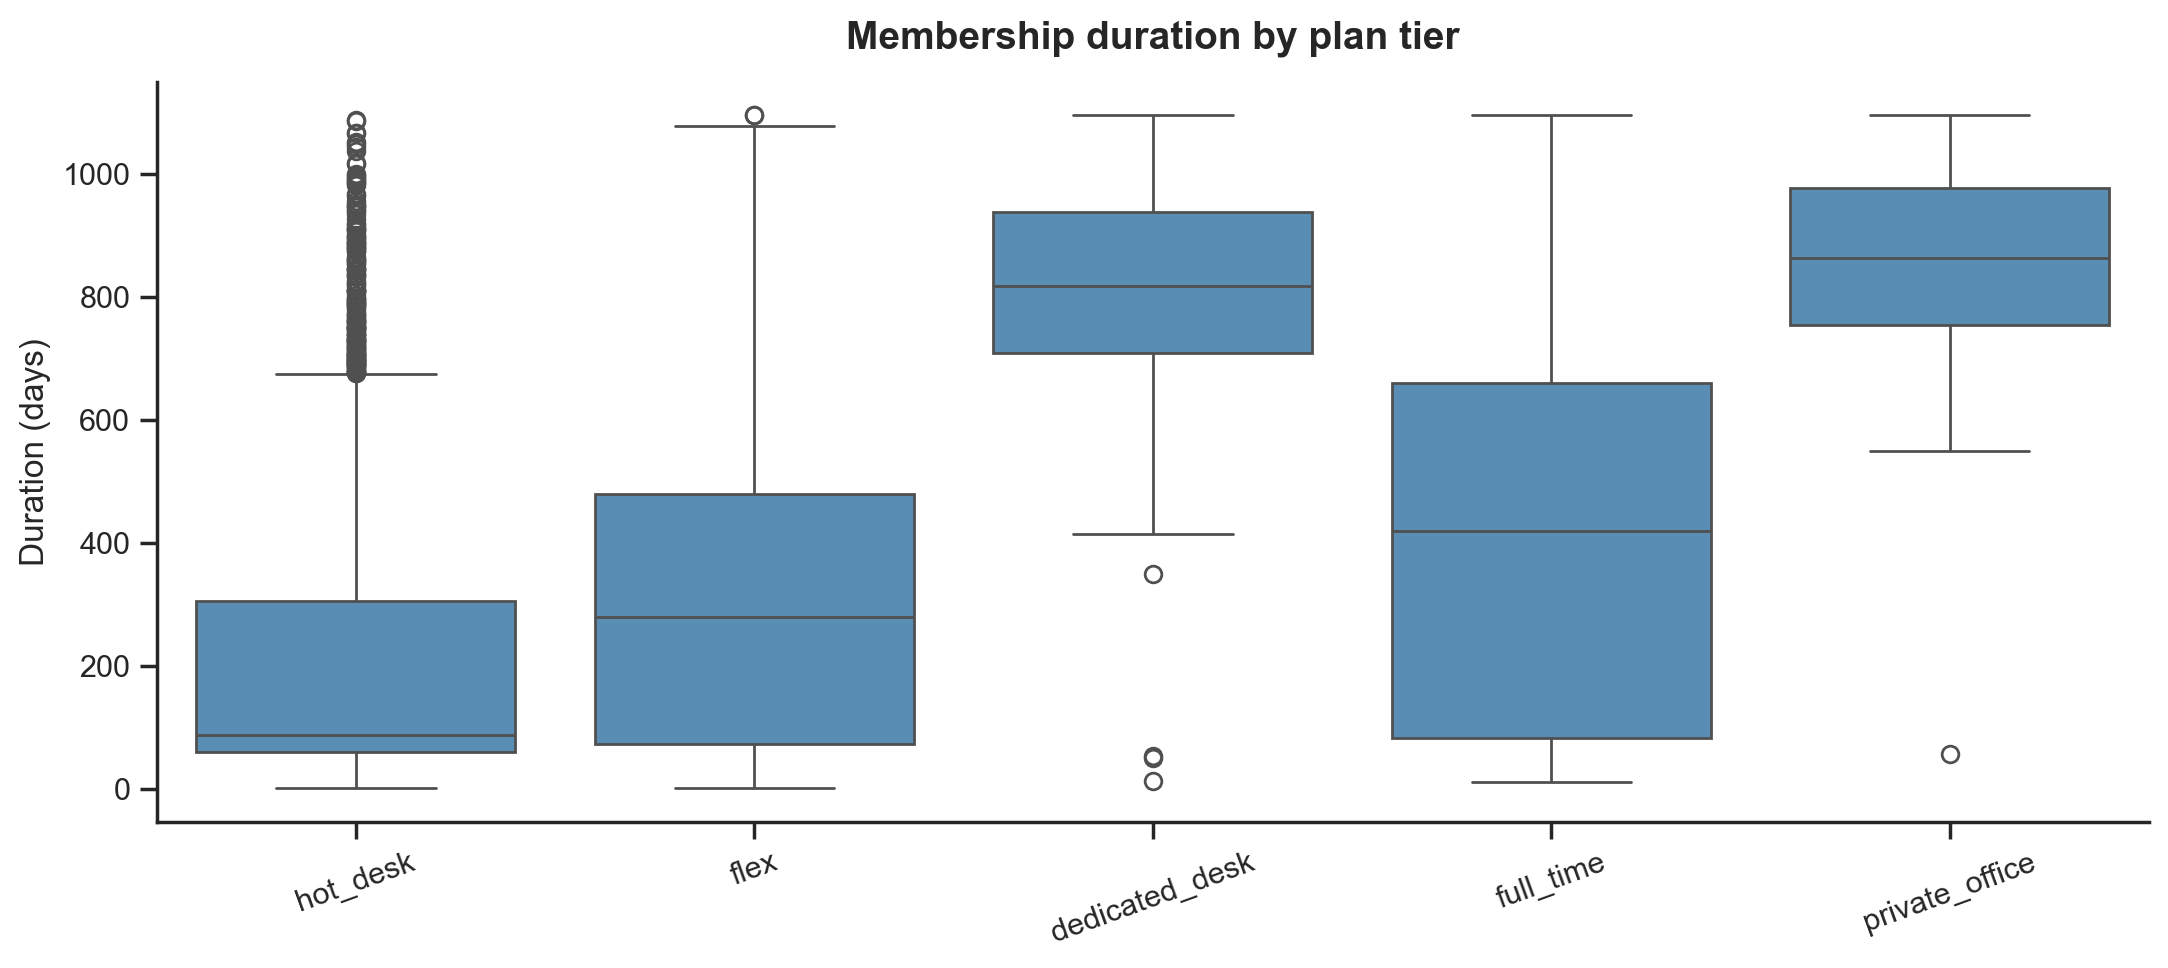

,count,mean,std,min,25%,50%,75%,max
plan_tier,,,,,,,,
hot_desk,4361.0,202.0,208.0,1.0,60.0,87.0,306.0,1087.0
flex,4207.0,303.0,235.0,2.0,72.0,279.0,480.0,1095.0
dedicated_desk,649.0,818.0,152.0,13.0,708.0,817.0,938.0,1095.0
full_time,1476.0,425.0,302.0,11.0,83.0,420.0,660.0,1095.0
private_office,347.0,856.0,151.0,57.0,754.0,863.0,976.0,1095.0


In [52]:
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_tenure, x="plan_tier", y="tenure_days", order=tier_order,
            color=main_color, ax=ax)

ax.set_title("Membership duration by plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Duration (days)")
ax.tick_params(axis="x", rotation=20)
sns.despine()
plt.tight_layout()
plt.show()

df_tenure.groupby("plan_tier")["tenure_days"].describe().loc[tier_order].round(0)

`dedicated_desk` and `private_office` are the plans with the longest-lasting customers (median duration of about 817 and 863 days, respectively), while `full_time` is the most heterogeneous plan, with durations spread widely (IQR from 83 to 660 days), possibly reflecting a group of customers who leave quickly alongside a larger group who stay much longer.

`hot_desk` has the shortest durations, with a strongly right-skewed distribution: half of the customers who left did so within 87 days, far below the median of `flex` (279 days), despite both plans having a similar number of customers who left (4,361 vs. 4,207).

These durations only cover customers who already left, and cheaper plans have more recent starts, so absolute values are likely underestimated for them.

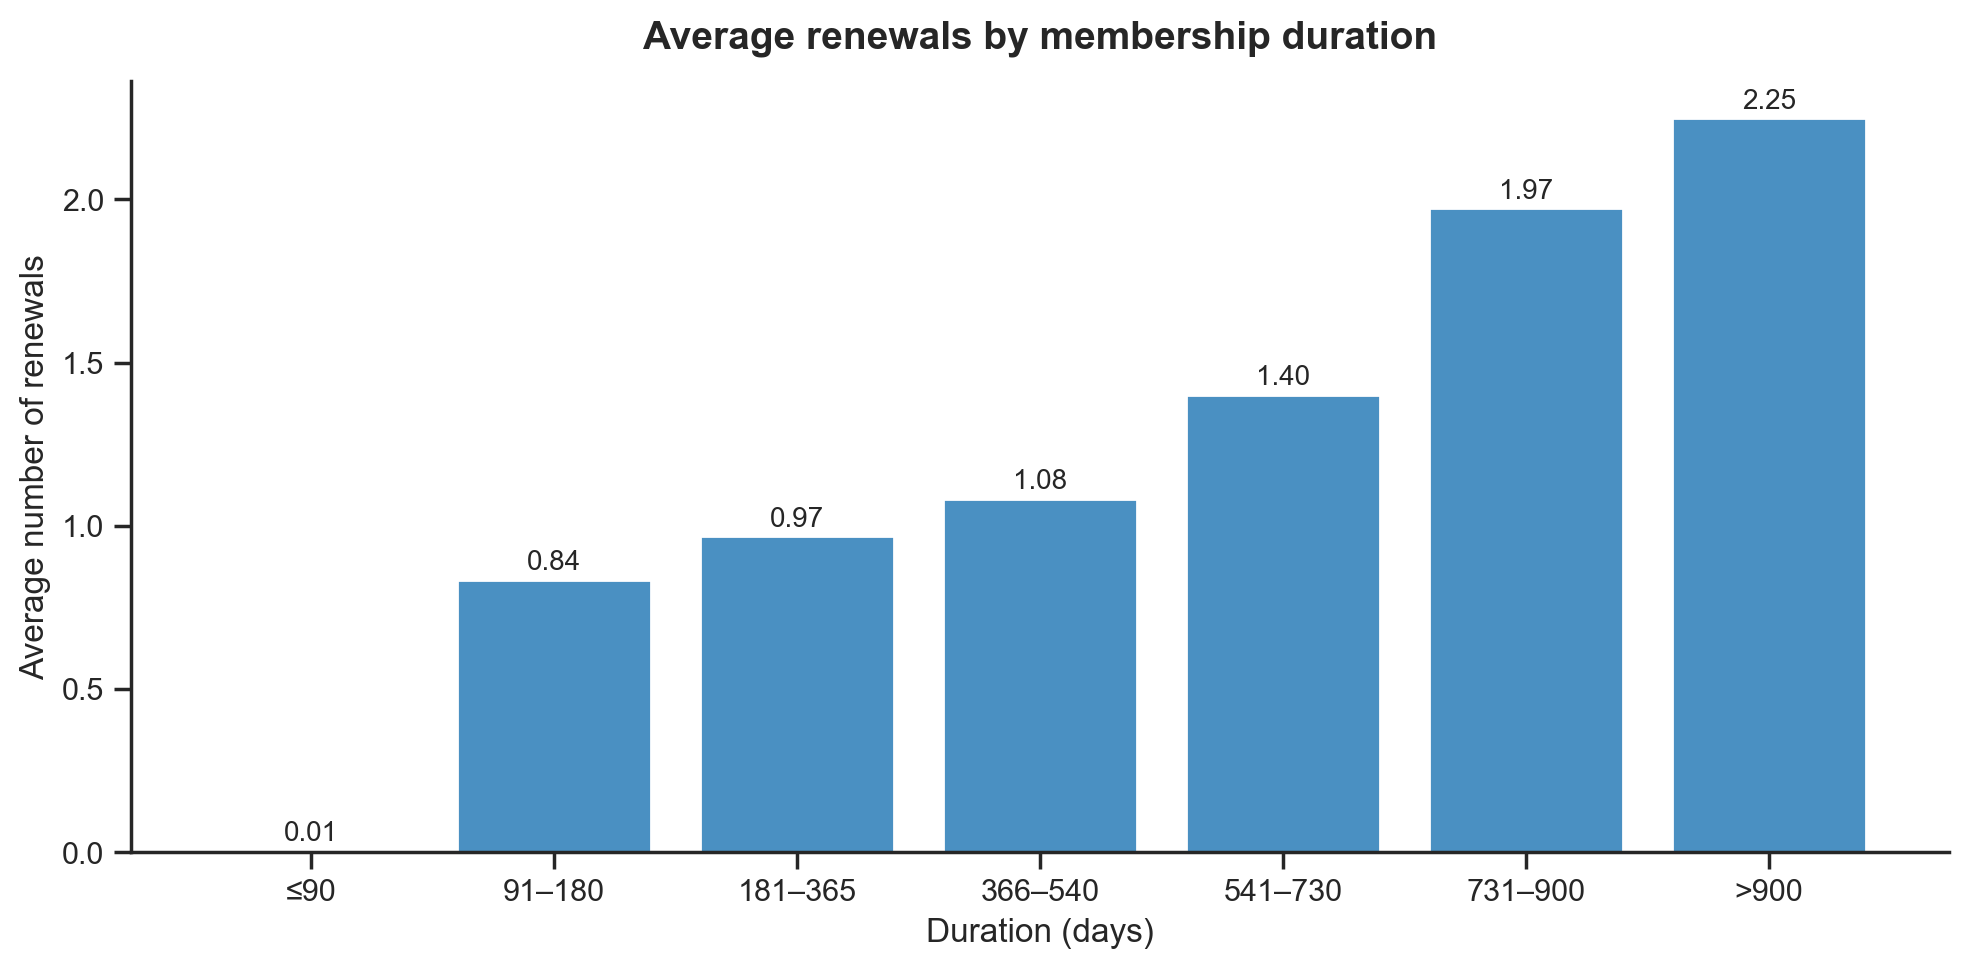

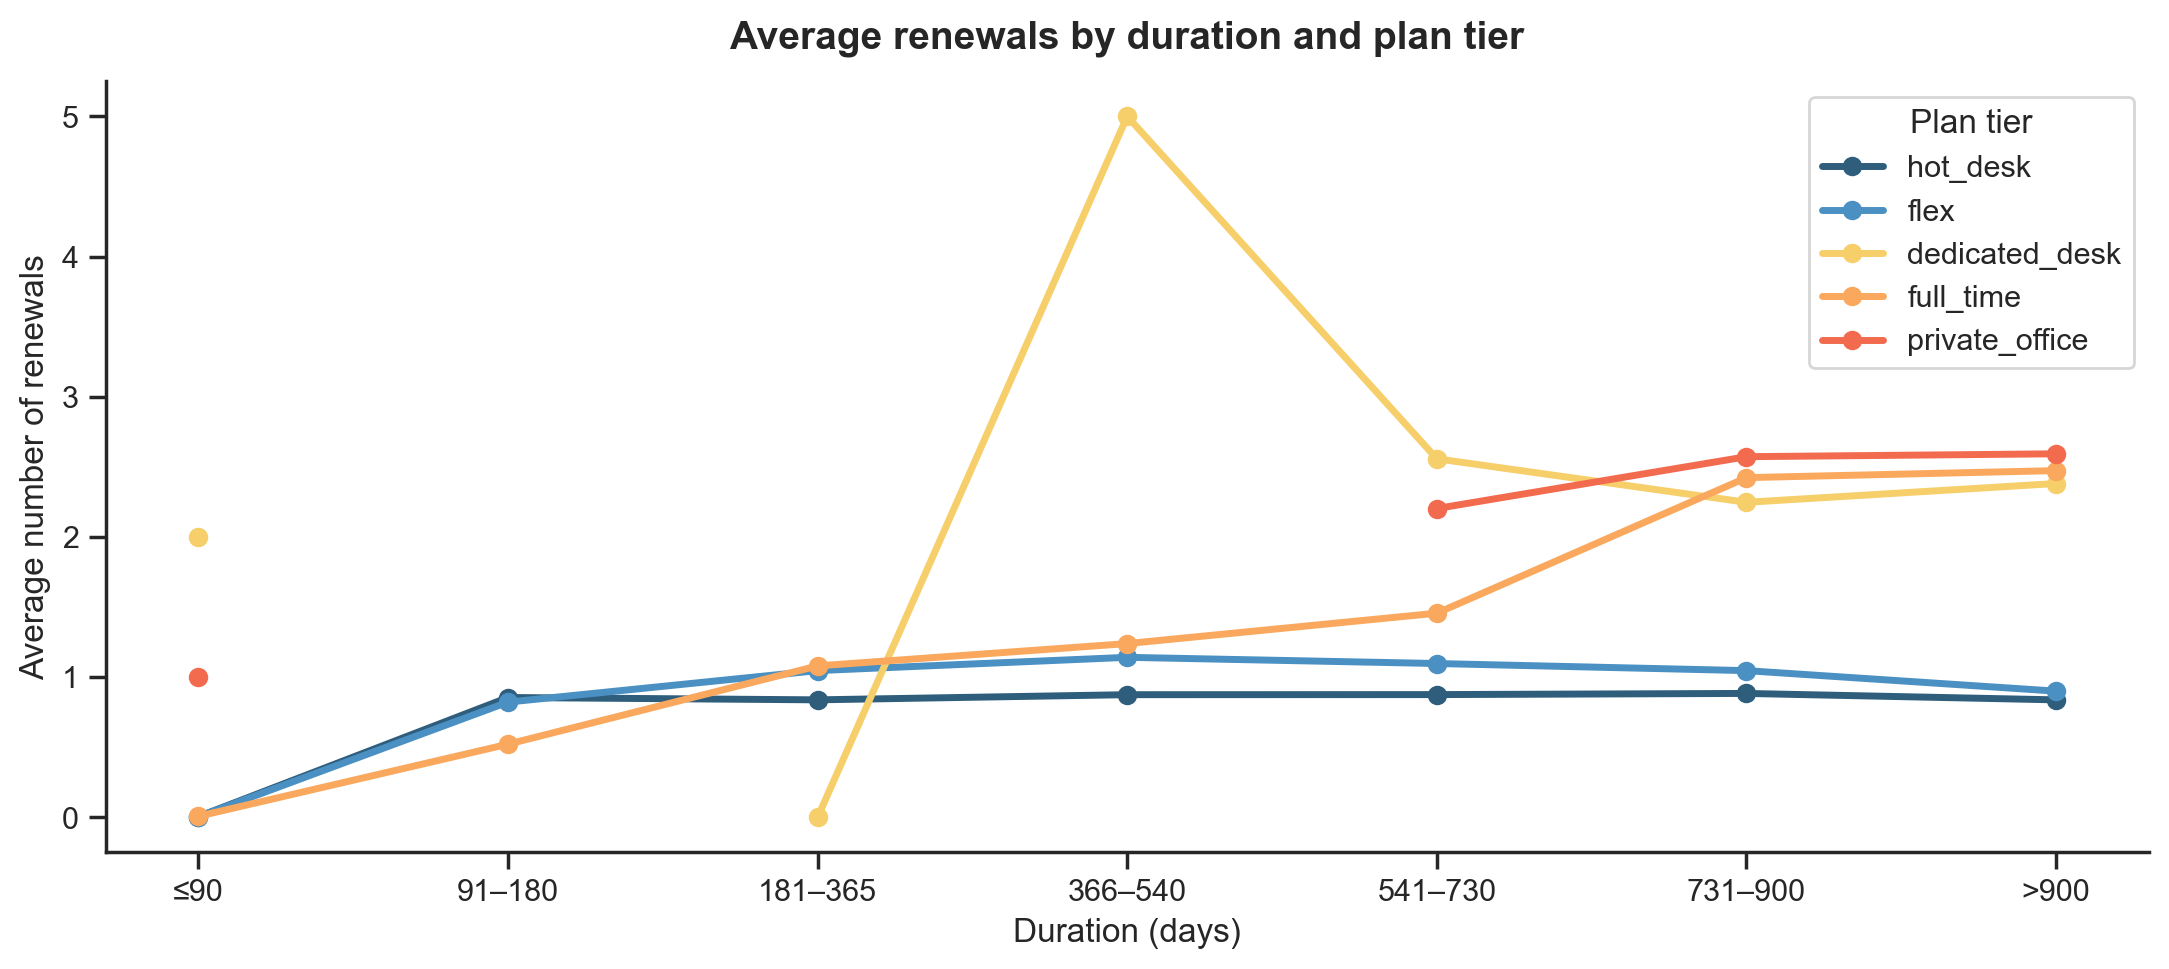

In [53]:
# df_tenure vem da célula anterior (clientes que saíram, datas coerentes)
df_ren = df_tenure[df_tenure["n_renewals"] >= 0].copy()

df_ren["tenure_bin"] = pd.cut(
    df_ren["tenure_days"],
    bins=[0, 90, 180, 365, 540, 730, 900, 1100],
    labels=["≤90", "91–180", "181–365", "366–540", "541–730", "731–900", ">900"]
)

# 1) média de renovações por faixa de duração
mean_by_bin = df_ren.groupby("tenure_bin", observed=True)["n_renewals"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(mean_by_bin.index.astype(str), mean_by_bin.values, color=main_color)
for i, v in enumerate(mean_by_bin.values):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=10)
ax.set_title("Average renewals by membership duration", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
sns.despine()
plt.tight_layout()
plt.show()

# 2) o mesmo, por plano
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
by_tier = (df_ren.groupby(["tenure_bin", "plan_tier"], observed=True)["n_renewals"]
           .mean().unstack()[tier_order])

fig, ax = plt.subplots(figsize=(11, 5))
by_tier.plot(ax=ax, marker="o", linewidth=2.5,
             color=colors)
ax.set_title("Average renewals by duration and plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
ax.legend(title="Plan tier", frameon=True, fancybox=True)
sns.despine()
plt.tight_layout()
plt.show()

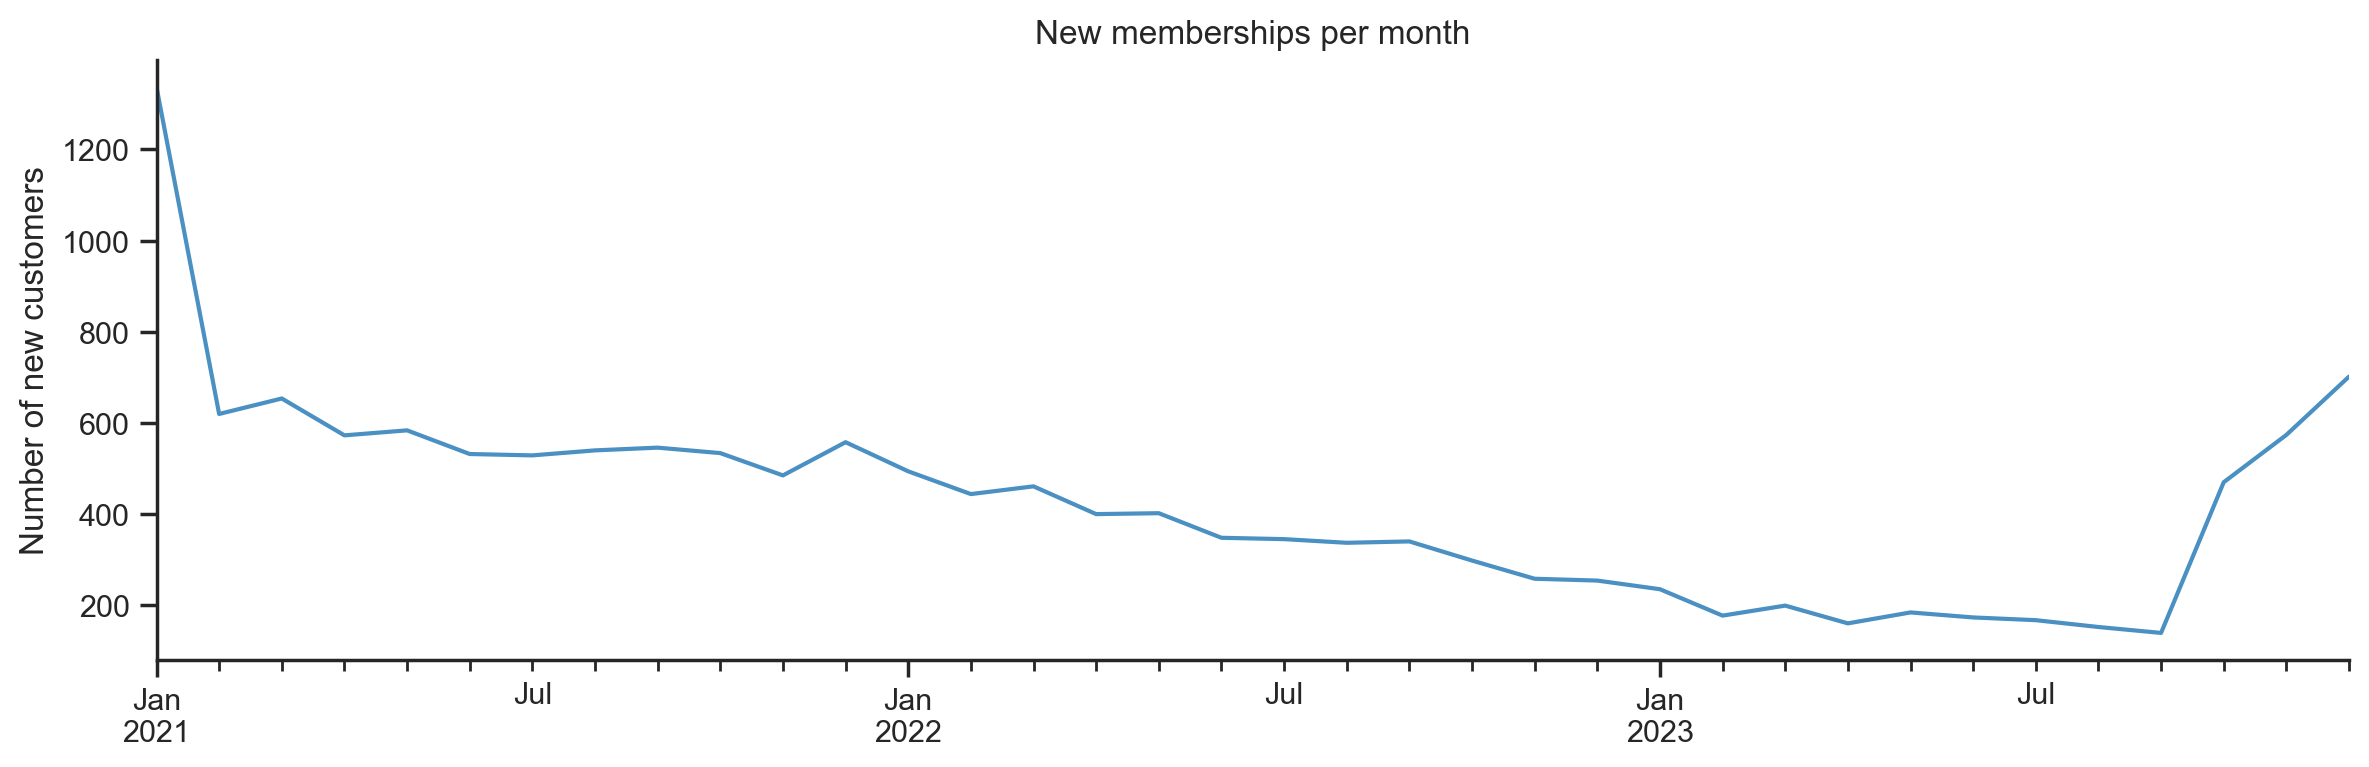

In [54]:
new_per_month = df_nodups.groupby(df_nodups["membership_start"].dt.to_period("M")).size()

plt.figure(figsize=(12, 4))
new_per_month.plot(color=main_color)
plt.title("New memberships per month")
plt.xlabel("")
plt.ylabel("Number of new customers")
sns.despine()
plt.tight_layout()
plt.show()

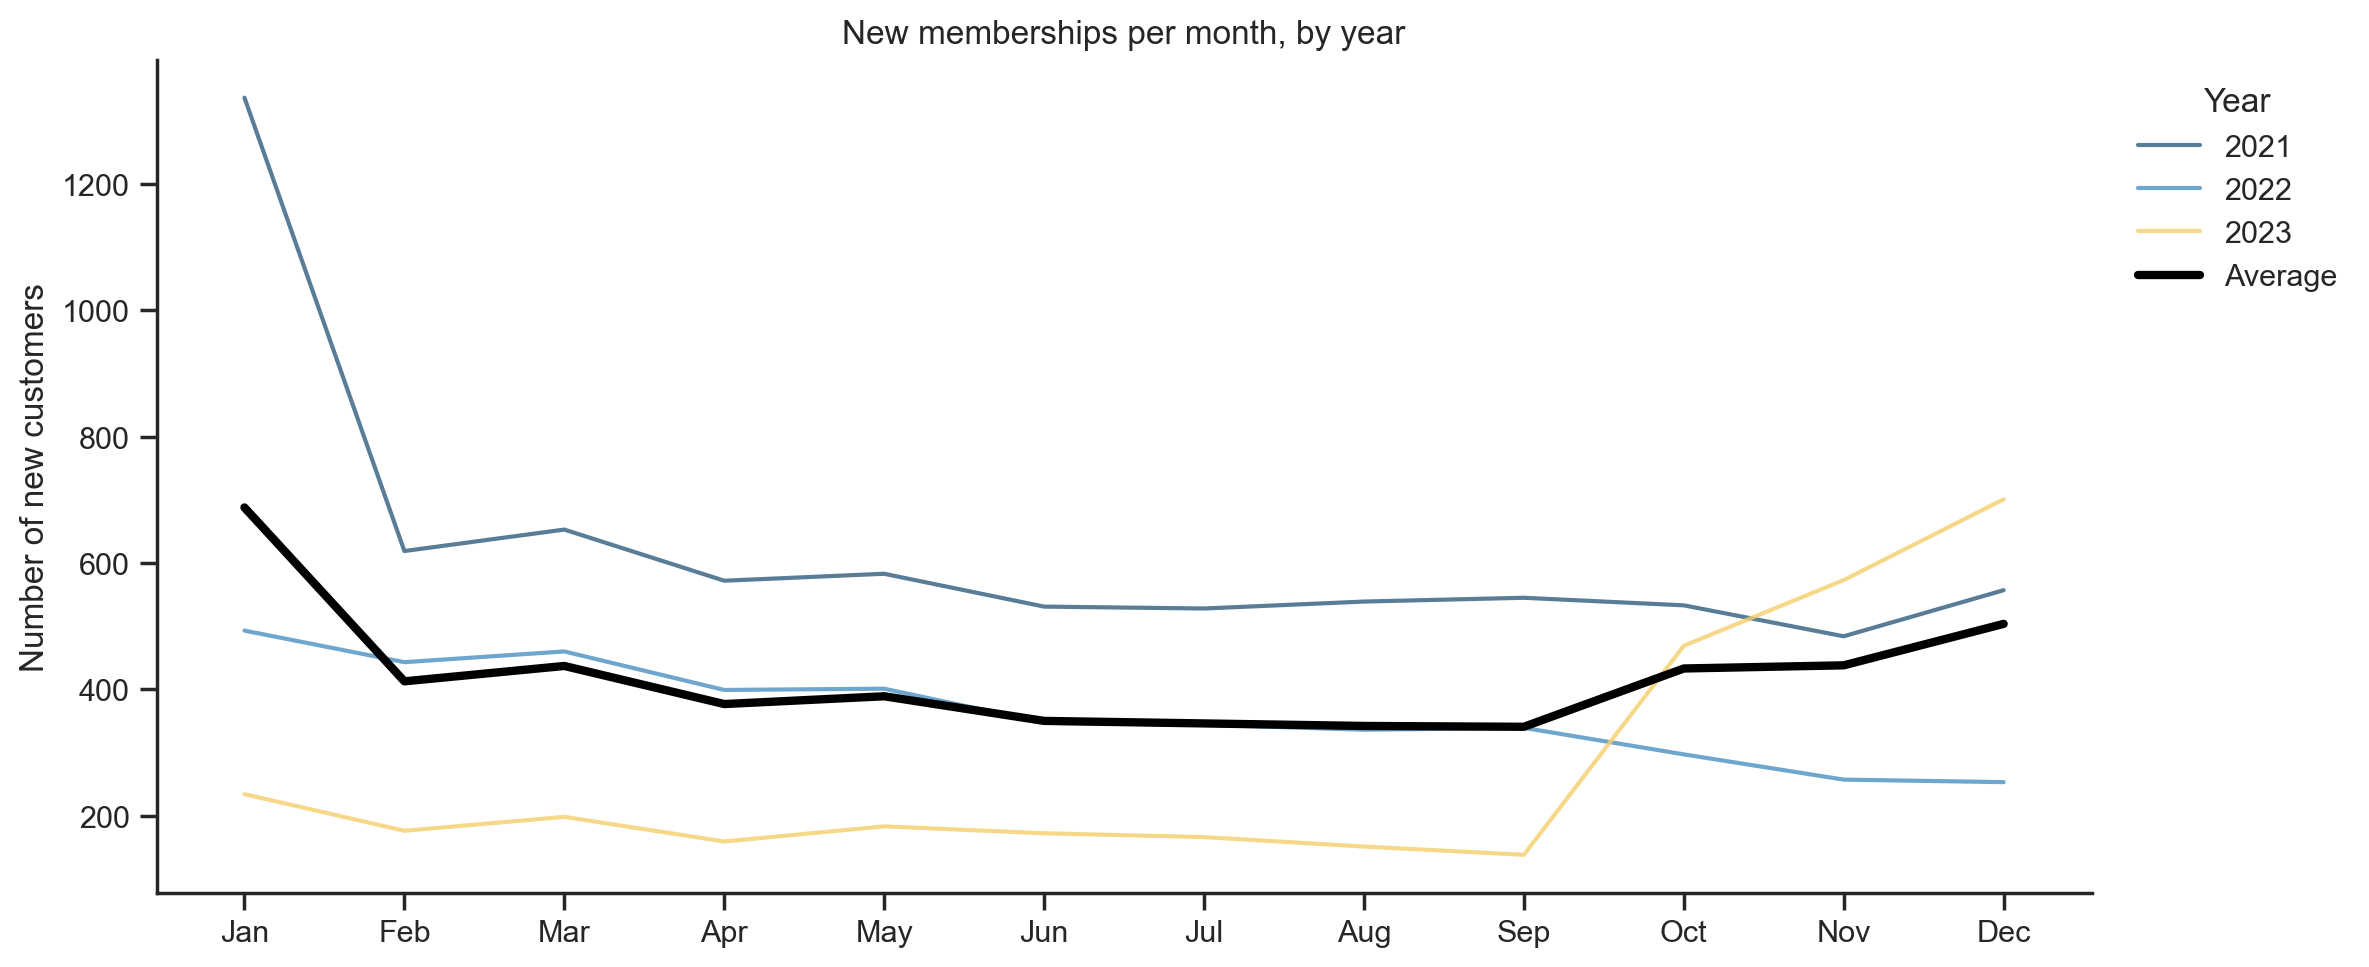

In [55]:
# nº de novos clientes por (ano, mês)
tmp = df_nodups.copy()
tmp["year"] = tmp["membership_start"].dt.year
tmp["month"] = tmp["membership_start"].dt.month

pivot = tmp.pivot_table(index="month", columns="year", values="membership_start", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
for color, year in zip(colors, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="black", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("New memberships per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

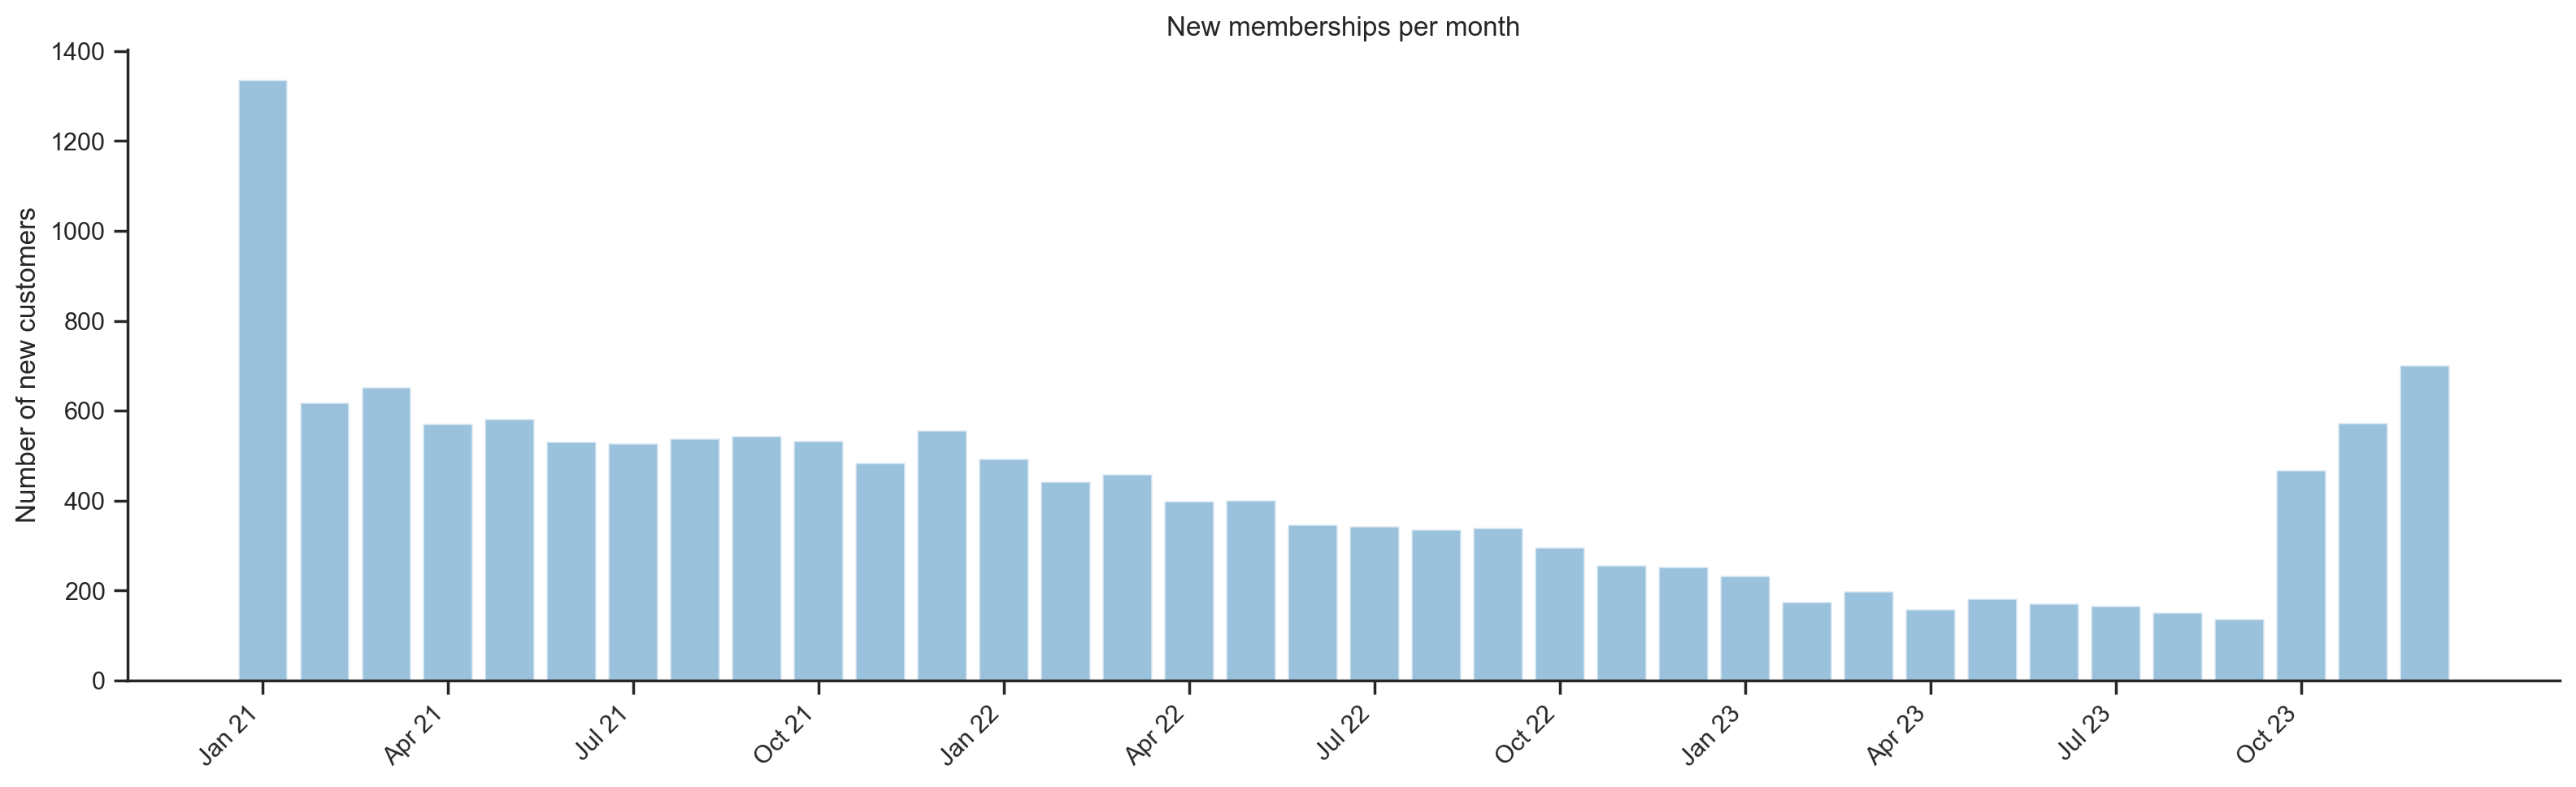

In [56]:
# nº de novos clientes por mês (inclui meses com 0)
monthly = df_nodups.set_index("membership_start").resample("MS").size()

# tendência suavizada (média móvel de 6 meses)
trend = monthly.rolling(6, center=True, min_periods=1).mean()

labels = monthly.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(range(len(monthly)), monthly.values, color=main_color, alpha=0.55, width=0.8)

step = 3
ax.set_xticks(range(0, len(monthly), step))
ax.set_xticklabels(labels[::step], rotation=45, ha="right")

ax.set_title("New memberships per month")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
sns.despine()
plt.tight_layout()
plt.show()

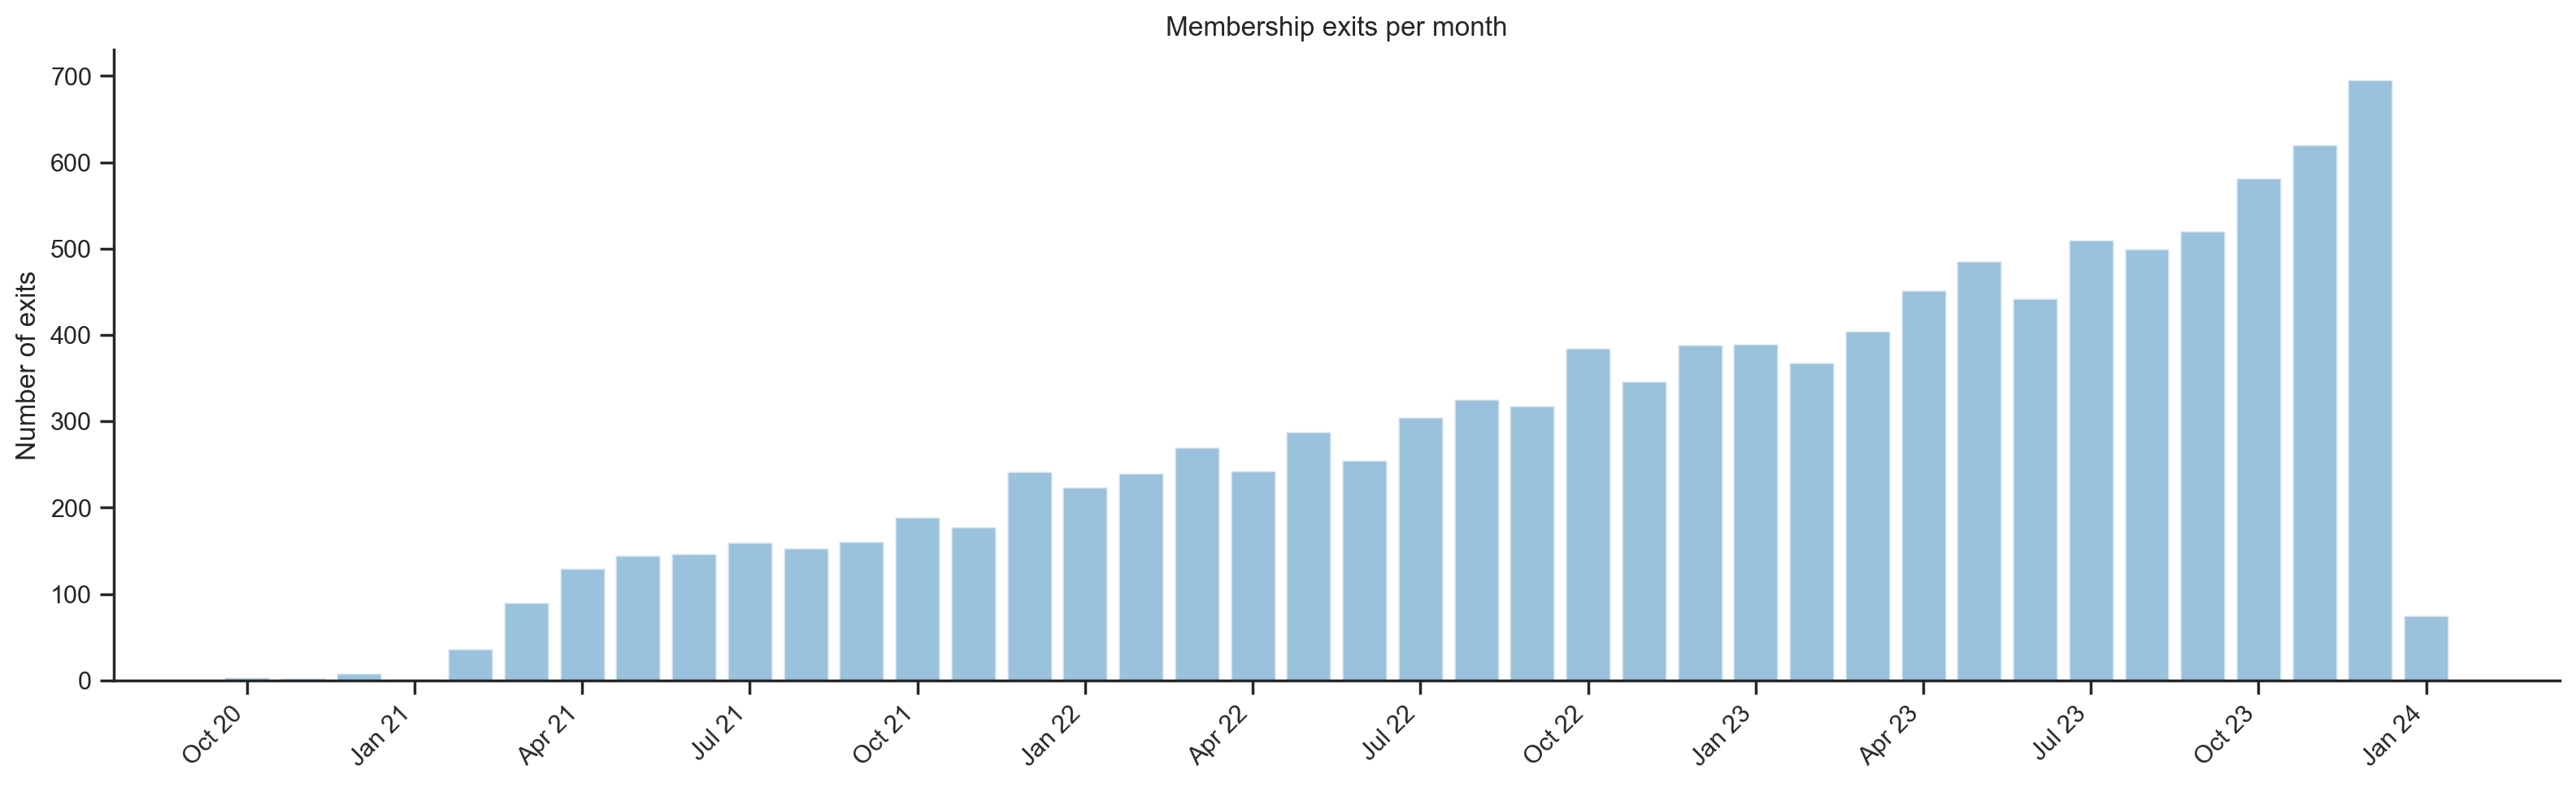

In [57]:
# só saídas reais (exclui o placeholder de 1970)
exits = df_nodups.loc[df_nodups["membership_end"] != pd.Timestamp("1970-01-01"), "membership_end"]

# nº de saídas por mês (inclui meses com 0)
monthly_exit = exits.to_frame().set_index("membership_end").resample("MS").size()

# tendência suavizada (média móvel de 6 meses)
trend_exit = monthly_exit.rolling(6, center=True, min_periods=1).mean()

labels = monthly_exit.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(16, 5))

ax.bar(range(len(monthly_exit)), monthly_exit.values, color=main_color, alpha=0.55, width=0.8)
step = 3
ax.set_xticks(range(0, len(monthly_exit), step))
ax.set_xticklabels(labels[::step], rotation=45, ha="right")

ax.set_title("Membership exits per month")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
sns.despine()
plt.tight_layout()
plt.show()

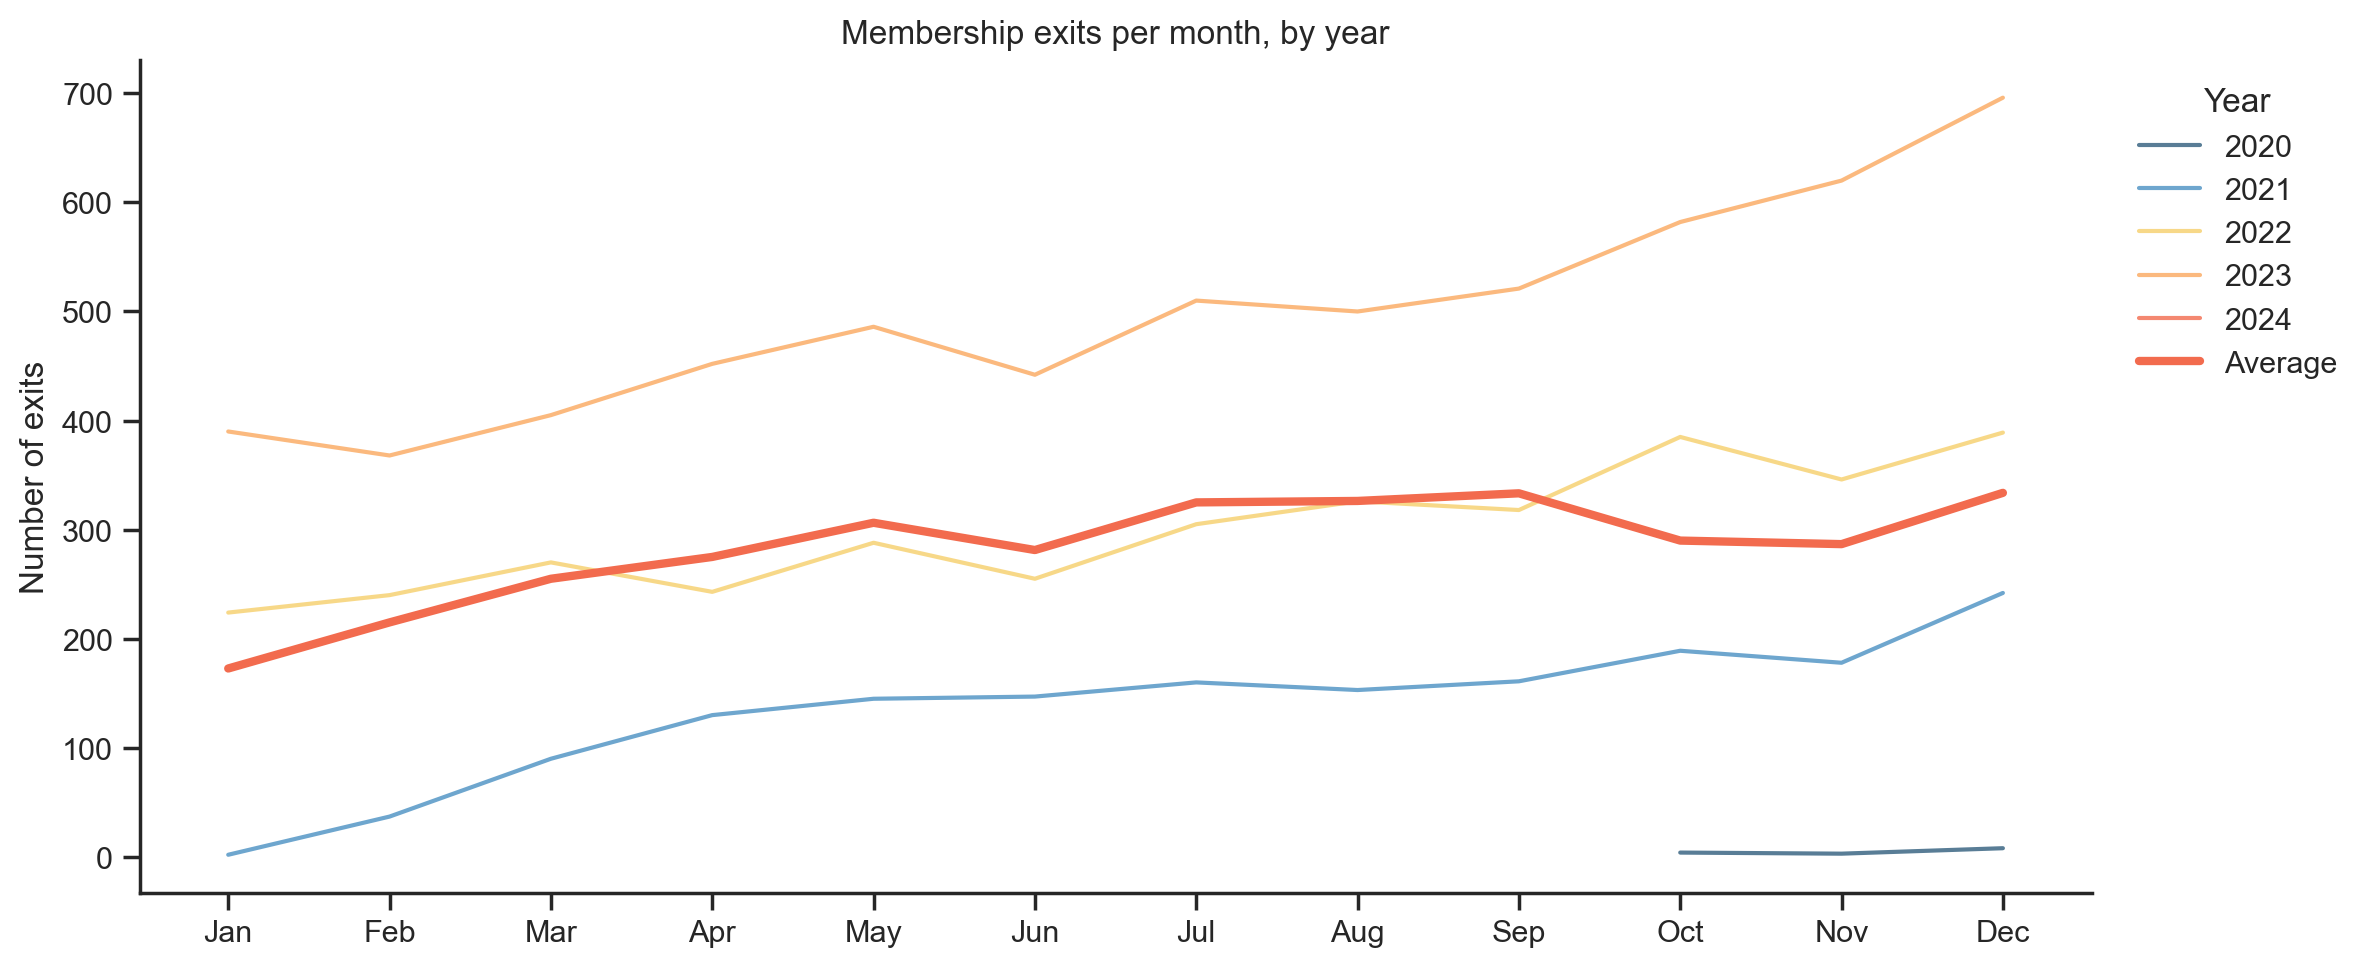

In [58]:
# só saídas reais (exclui o placeholder de 1970)
tmp = df_nodups.loc[df_nodups["membership_end"] != pd.Timestamp("1970-01-01")].copy()
tmp["year"] = tmp["membership_end"].dt.year
tmp["month"] = tmp["membership_end"].dt.month

# nº de saídas por (ano, mês)
pivot = tmp.pivot_table(index="month", columns="year", values="membership_end", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
for color, year in zip(colors, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="#F26B4E", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Membership exits per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

<b><font size="6" color="#FAA85E">5. Categorical Features Visualization</font></b><br>

In this section we built an interactive dashboard to analyze the categorical features and to compare them with the metric features.

In [61]:
object_features = ["industry", "country", "gender", "plan_tier"]
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
# Stringify dates so the grid can serialize them
df_grid = df_nodups.copy()
for c in date_cols:
    if c in df_grid.columns:
        df_grid[c] = df_grid[c].astype(str)

# Radio buttons: no raw date columns
radio_features = [c for c in metric_features
                  if c not in ["membership_start", "membership_end", "last_badge_swipe"]]

external_stylesheets = ['https://codepen.io/chriddyp/pen/bWLwgP.css']
app = Dash(external_stylesheets=external_stylesheets)

app.layout = html.Div(
    style={
        'backgroundColor': '#F7F9FB',
        'color': '#264653',
        'fontFamily': 'Helvetica, Arial, sans-serif',
        'padding': '20px',
        'minHeight': '100vh',
    },
    children=[
        # Title
        html.Div(className='row app-title', children='My First App with Data, Graph, and Controls',
         style={'textAlign': 'center', 'color': colors[0], 'fontSize': 36,
                'fontWeight': 'bold', 'marginBottom': '20px'}),
        
        # Table
        html.Div(className='row', children=[
            dag.AgGrid(
                rowData=df_grid.to_dict('records'),
                columnDefs=[{"field": i, "filter": True, "sortable": True} for i in df_grid.columns],
                defaultColDef={"resizable": True},
                dashGridOptions={"pagination": True, "paginationPageSize": 15},
                )
                ]),
        
        # Controls row 1: metric + aggregation
        html.Div(className='row', children=[
        html.Div(className='six columns', children=[
            dcc.Dropdown(options=radio_features, value=radio_features[0],
            id='metric-dropdown', clearable=False),
                        ]),
        ]),
        html.Div(className='row', children=[
            dcc.RadioItems(options=['avg', 'sum', 'count', 'min', 'max'], value='avg',
                           inline=True, id='agg-radio'),
                           ]),
        
        # Controls row 2: grouping + filters
        html.Div(className='row', children=[
            html.Div(className='four columns', children=[
                    dcc.Dropdown(options=object_features, value='industry',
                                id='group-dropdown', clearable=False),
                                ]),
            html.Div(className='four columns', children=[
                dcc.Checklist(options=sorted(df_nodups['plan_tier'].dropna().unique()),
                            value=list(df_nodups['plan_tier'].dropna().unique()),
                            inline=True, id='tier-filter'),
                            ]),
            html.Div(className='four columns', children=[
                dcc.RadioItems(options=['All', 'Team', 'Individual'], value='All',
                            inline=True, id='team-filter'),
                            ]),
                            ]),
            
            # Table + histogram
        html.Div(className='row', children=[
            html.Div(className='seven columns', children=[
                            dcc.Graph(figure={}, id='norm-histo-chart-final')
                        ]),
            html.Div(className='five columns', children=[
                dcc.Graph(figure={}, id='histo-chart-final')
            ]),
        ]),
        
            # Second graph (boxplot)
            html.Div(className='row', children=[
                dcc.Graph(figure={}, id='box-chart')
            ]),
        ],
)


@callback(
        Output('norm-histo-chart-final', 'figure'),
        Output('histo-chart-final', 'figure'),
        Output('box-chart', 'figure'),
        Input('metric-dropdown', 'value'),
        Input('group-dropdown', 'value'),
        Input('tier-filter', 'value'),
        Input('team-filter', 'value'),
        Input('agg-radio', 'value'),
)
def update_graph(col_chosen, group, tiers, team, agg):
    d = df_nodups[df_nodups['plan_tier'].isin(tiers)]
    if team == 'Team':
        d = d[d['is_team_account']]
    elif team == 'Individual':
        d = d[~d['is_team_account']]

    fig1 = px.histogram(d, x=group, y=col_chosen, histfunc=agg,
                    color="plan_tier", barmode="group",
                    color_discrete_sequence=colors)
    fig1.update_layout(template='simple_white')

    fig2 = px.histogram(d, x=group, y=col_chosen, histfunc=agg,
                        color="plan_tier", barmode="stack", barnorm="percent",
                        color_discrete_sequence=colors)
    fig2.update_layout(template='simple_white')

    fig3 = px.box(d, x=group, y=col_chosen, color_discrete_sequence=colors)
    fig3.update_layout(template='simple_white')

    for f in (fig1, fig2, fig3):
        f.update_layout(
        template='simple_white',
        paper_bgcolor='white',       # area around the plot
        plot_bgcolor='white',        # plot area
        font=dict(family='Helvetica', color='#264653', size=13),
        title_font_color=colors[0],
        )
        f.update_xaxes(showgrid=False, linecolor='#264653')
        f.update_yaxes(gridcolor='#E5E5E5')
    return fig1, fig2, fig3


if __name__ == '__main__':
    app.run(debug=True)